# Fuel Efficiency Regression

**Family:** End-to-end project | **Dataset:** `auto_mpg` | **Task:** regression

Predict miles per gallon from engine and weight, with a model comparison and residual review. Substitutes the energy forecasting case for which no open data could be downloaded.

## Table of Contents

- 1. Problem statement
- 2. Business or research context
- 3. Dataset documentation
- 4. Research references
- 5. Exploratory analysis
- 6. Preprocessing
- 7. Model selection
- 8. Model training
- 9. Evaluation
- 10. Comparison
- 11. Interpretation
- 12. Limitations
- 13. Final recommendations

## 1. Problem statement

Predict a car's fuel economy from its design.

## 2. Business or research context

Vehicle design teams trade weight, power and efficiency. A transparent model shows the cost of each design choice. The dataset is old (1970 to 1982), so conclusions about modern cars do not follow.

## 3. Dataset documentation

**Auto MPG** (Quinlan, 1993), UCI Machine Learning Repository, licence CC BY 4.0, DOI 10.24432/C5859H. 392 cars from 1970 to 1982 without missing horsepower (as shipped in `mlxtend`). Target `mpg`. Features: `cylinders`, `displacement`, `horsepower`, `weight`, `acceleration`, `model_year`, `origin` (1 US, 2 Europe, 3 Japan). All numeric. Limit: old cars only, so conclusions do not transfer to modern vehicles.

## 4. Research references

Verification status is from the build environment on 2026-11-17. Entries marked *not verified* must be checked before citing.

- Hoerl, A. E. and Kennard, R. W. (1970). *Ridge Regression: Biased Estimation for Nonorthogonal Problems*. Technometrics 12(1):55-67. https://doi.org/10.1080/00401706.1970.10488634 Verification: Crossref 2026-11-17
- Tibshirani, R. (1996). *Regression Shrinkage and Selection Via the Lasso*. Journal of the Royal Statistical Society B 58(1):267-288. https://doi.org/10.1111/j.2517-6161.1996.tb02080.x Verification: Crossref 2026-11-17
- Friedman, J. H. (2001). *Greedy function approximation: A gradient boosting machine*. The Annals of Statistics 29(5):1189-1232. https://doi.org/10.1214/aos/1013203451 Verification: Crossref 2026-11-17

Ridge, lasso and gradient boosting are compared, with a linear baseline.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score
from ml_lab.data import load_dataset
from ml_lab.preprocessing import split_three_way, make_model_pipeline, build_preprocessor
from ml_lab.evaluation import evaluate_estimator, internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz
PROJECT_ID = "fuel_efficiency_regression"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("auto_mpg")
X, y = bundle.X, bundle.y
Xtr, Xva, Xte, ytr, yva, yte = split_three_way(X, y, task="regression", seed=SEED)
print(len(Xtr), len(Xva), len(Xte))

234 79 79


## 5. Exploratory analysis

Target distribution and the relation with weight.

,correlation with mpg
weight,-0.83
displacement,-0.81
cylinders,-0.78
horsepower,-0.78
acceleration,0.42
origin,0.57
model_year,0.58


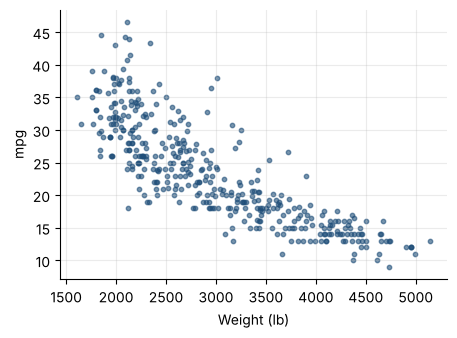

In [3]:
display(pd.concat([X, y.rename("mpg")], axis=1).corr()["mpg"].drop("mpg").round(2).sort_values().to_frame("correlation with mpg"))
fig, ax = plt.subplots(figsize=(5, 3.5)); ax.scatter(X["weight"], y, s=10, alpha=0.6); ax.set_xlabel("Weight (lb)"); ax.set_ylabel("mpg"); plt.show()

## 6. Preprocessing

Scaling inside the pipeline for linear models. Trees need none.

In [4]:
print(X.dtypes.to_dict())

{'cylinders': dtype('float64'), 'displacement': dtype('float64'), 'horsepower': dtype('float64'), 'weight': dtype('float64'), 'acceleration': dtype('float64'), 'model_year': dtype('float64'), 'origin': dtype('float64')}


## 7. Model selection

Linear regression, ridge (alpha chosen on validation), lasso and histogram gradient boosting. The metric is RMSE in miles per gallon.

In [5]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error
rmse = lambda a, b: float(mean_squared_error(a, b) ** 0.5)  # noqa: E731
best_alpha = {}
for name, cls_, alphas in [("ridge", Ridge, [0.01, 0.1, 1, 10, 100]), ("lasso", Lasso, [0.001, 0.01, 0.1, 1])]:
    scores = {a: rmse(yva, make_model_pipeline(Xtr, cls_(alpha=a)).fit(Xtr, ytr).predict(Xva)) for a in alphas}
    best_alpha[name] = min(scores, key=scores.get)
cands = {"dummy": (DummyRegressor(), True), "linear": (LinearRegression(), True), "ridge": (Ridge(alpha=best_alpha["ridge"]), True), "lasso": (Lasso(alpha=best_alpha["lasso"]), True),
         "hist_gradient_boosting": (HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED), False)}
fitted = {n: make_model_pipeline(Xtr, m, scale=s).fit(Xtr, ytr) for n, (m, s) in cands.items()}
sel = pd.Series({n: rmse(yva, f.predict(Xva)) for n, f in fitted.items()}, name="validation RMSE")
display(sel.round(3).to_frame()); BEST = sel.drop("dummy").idxmin(); print("selected:", BEST, "| alphas:", best_alpha)

,validation RMSE
dummy,7.001
linear,2.843
ridge,2.813
lasso,2.843
hist_gradient_boosting,3.236


selected: ridge | alphas: {'ridge': 10, 'lasso': 0.001}


## 8. Model training

Refit the selected model on training plus validation rows and run five fold cross validation.

In [6]:
Xtv, ytv = pd.concat([Xtr, Xva]), pd.concat([ytr, yva])
m, s = cands[BEST]
final = make_model_pipeline(Xtv, clone(m), scale=s).fit(Xtv, ytv)
cv = cross_val_score(make_model_pipeline(Xtv, clone(m), scale=s), Xtv, ytv, cv=KFold(5, shuffle=True, random_state=SEED), scoring="neg_root_mean_squared_error")
print(f"CV RMSE {-cv.mean():.3f} +- {cv.std(ddof=1):.3f}")

CV RMSE 3.437 +- 0.316


## 9. Evaluation

Test set, scored once, with the dummy baseline.

In [7]:
m_test = evaluate_estimator(final, Xte, yte, "regression")
m_base = evaluate_estimator(fitted["dummy"], Xte, yte, "regression")
METRICS = {**{f"test_{k}": v for k, v in m_test.items()}, "baseline_RMSE": m_base["RMSE"], "cv_RMSE_mean": float(-cv.mean()), "cv_RMSE_std": float(cv.std(ddof=1))}
CONFIG = {"selected_model": BEST, "ridge_alpha": best_alpha["ridge"], "lasso_alpha": best_alpha["lasso"]}
EXTRA = {"validation_RMSE": sel.round(4).to_dict()}
ALGORITHM = BEST
display(pd.DataFrame({"model": m_test, "dummy": m_base}).round(3))

record = ExperimentRecord(notebook=PROJECT_ID, family="project", algorithm=ALGORITHM, dataset="auto_mpg", task="regression", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

,model,dummy
MAE,2.453,5.899
MSE,11.102,51.972
RMSE,3.332,7.209
R2,0.782,-0.018
MAPE_percent,11.874,30.533


saved: experiments/results/fuel_efficiency_regression.json


,metric
test_MAE,2.4531
test_MSE,11.1017
test_RMSE,3.3319
test_R2,0.7825
test_MAPE_percent,11.8737
baseline_RMSE,7.2091
cv_RMSE_mean,3.4368
cv_RMSE_std,0.3162


## 10. Comparison

All models on the test rows, for comparison only.

In [8]:
display(pd.Series({n: rmse(yte, f.predict(Xte)) for n, f in fitted.items()}, name="test RMSE").round(3).to_frame())

,test RMSE
dummy,7.209
linear,3.257
ridge,3.346
lasso,3.259
hist_gradient_boosting,2.485


## 11. Interpretation

Residuals by origin, and permutation importance.

In [9]:
res_ = yte - final.predict(Xte)
display(res_.groupby(Xte["origin"]).agg(["mean", "std", "count"]).round(2))
imp = permutation_importance(final, Xte, yte, scoring="neg_root_mean_squared_error", n_repeats=10, random_state=SEED)
display(pd.Series(imp.importances_mean, index=Xte.columns).sort_values(ascending=False).round(3).to_frame("RMSE increase"))

,mean,std,count
origin,,,
1.0,0.39,2.60,43
2.0,-0.21,3.86,20
3.0,-2.33,3.79,16


,RMSE increase
weight,2.916
model_year,1.406
displacement,0.102
horsepower,0.083
origin,0.068
acceleration,0.018
cylinders,-0.036


## 12. Limitations

Cars from 1970 to 1982 only, 392 rows, 79 test rows. Weight, displacement and horsepower are strongly correlated, so single coefficients are unstable.

## 13. Final recommendations

Use the model to explain relative effects, not to predict modern cars. For a design tool collect current data and report prediction intervals.